# Identifying Curatorial Voice: Analysing Cataloguing Practice Across Collections at the National Library of Scotland

### James Baker [![orcid](https://orcid.org/sites/default/files/images/orcid_16x16.png)](https://orcid.org/0000-0002-2682-6922)
University of Southampton

[![cc-by](https://licensebuttons.net/l/by/4.0/88x31.png)](https://creativecommons.org/licenses/by/4.0/)
©James Baker. Published by De Gruyter in cooperation with the University of Luxembourg Centre for Contemporary and Digital History. This is an Open Access article distributed under the terms of the [Creative Commons Attribution License CC-BY](https://creativecommons.org/licenses/by/4.0/)

[![cc-by-nc-nd](https://licensebuttons.net/l/by-nc-nd/4.0/88x31.png)](https://creativecommons.org/licenses/by-nc-nd/4.0/)
©James Baker. Published by De Gruyter in cooperation with the University of Luxembourg Centre for Contemporary and Digital History. This is an Open Access article distributed under the terms of the [Creative Commons Attribution License CC-BY-NC-ND](https://creativecommons.org/licenses/by-nc-nd/4.0/)

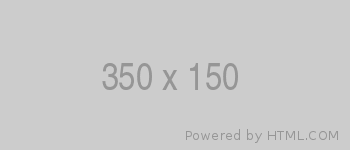

In [1]:
from IPython.display import Image, display

display(Image("./media/placeholder.png"))

cataloguing, catalogues as data, curatorial voice, National Library of Scotland, cultural heritage, unsupervised clustering

Cataloguers work to formal standards, but they also learn conventions from those who came before them and pass those conventions on. Historians of cataloguing know this tacit craft exists, and corpus-linguistic work has recovered the voice of single, named cataloguers from large bodies of their entries. What happens when the cataloguers are not named, little institutional memory survives, and the records sit in one large catalogue built from many collections? This article asks what the catalogue of the National Library of Scotland (NLS) shows about how cataloguing practice passed between collections and media, and how far a computational method can recover traces of that practice.

## Introduction

### Setting up the data and code

This cell and the next load the libraries and set the paths used throughout the article. The code and data sit in the `script/` folder of the article's repository; nothing is downloaded while the article runs.

In [2]:
import sys
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET
from platform import python_version

import numpy as np
import pandas as pd

ROOT = Path.cwd()
SCRIPT = ROOT / "script"
CORPUS_XML = SCRIPT / "data" / "nls-merged-corpus-v2.xml"
DERIVED = SCRIPT / "derived-data"
SWEEP = SCRIPT / "parameter-sweep" / "derived-data"
EMBED = SCRIPT / "embeddings-comparison" / "derived-data"
PILOT_RUN = "20260708-152108"      # the run reported in the article
EMBED_RUN = "20261020-123448"      # the language-model comparison

sys.path.insert(0, str(SCRIPT / "code"))
import structural_masking_v1 as sm

pd.set_option("display.max_colwidth", 90)
print("Python", python_version(), "| corpus found:", CORPUS_XML.exists())

Python 3.11.14 | corpus found: True


## The catalogue records

### Loading the merged corpus

The merged corpus is one XML file holding all 26,957 records. The loader below is the one used in the pilot: it keeps each record's identifier, collection, description fields, and number of subject headings.

In [3]:
NS = {"mc": "http://purl.org/nls-merged-corpus/1.0/"}

def load_records(path):
    recs = []
    for _, d in ET.iterparse(str(path), events=("end",)):
        if not d.tag.endswith("Description"):
            continue
        descs = [e.text for e in d if e.tag.endswith("description") and e.text]
        nsub = sum(1 for e in d if e.tag.endswith("subject"))
        coll = d.find("mc:collection", NS); rid = d.find("mc:record_id", NS)
        recs.append({"record_id": rid.text if rid is not None else "?",
                     "collection": coll.text if coll is not None else "?",
                     "descriptions": descs, "n_subjects": nsub})
        d.clear()
    return recs

records = load_records(CORPUS_XML)
print(f"{len(records):,} records")

26,957 records


In [4]:
pd.Series(Counter(r["collection"] for r in records)).sort_values(ascending=False).to_frame("records")

,records
mia,23491
eb,2438
hd,537
tp,190
tb,91
sp,72
jw,62
fb,40
jk,23
ja,13


## A first attempt: matching the text of records

### Text matching (stage 1), from saved results

In [5]:
communities = pd.read_csv(DERIVED / "communities_nls-merged-corpus_20260609-082911.tsv", sep="\t")
communities.head()

,record_id,community_id
0,eb_74891152,0
1,eb_74893033,0
2,eb_74891383,0
3,eb_74891845,0
4,eb_74892121,0


## Reading for how records were written

### Splitting a description into clauses and measuring their shape

Each description is split into clauses, and each clause is described by seventeen measures that carry no vocabulary. The cell below applies this to one record.

In [6]:
example = next(r for r in records if r["collection"] == "tb" and r["descriptions"])
clauses = sm.segment_record(example["descriptions"])
pd.DataFrame([sm.clause_features(c) for c in clauses], columns=sm.FEATURE_NAMES,
             index=[c[:40] for c in clauses]).round(2).T

,Date of event depicted: 1879,Photograph of wrecked piers after collap
log_n_tokens,1.79,2.64
mean_token_len,4.60,4.77
digit_char_ratio,0.14,0.00
has_timecode,0.00,0.00
n_timecodes_log,0.00,0.00
comma_per_token,0.00,0.00
semicolon_per_token,0.00,0.00
colon_per_token,0.20,0.00
period_per_token,0.00,0.15
bracket_per_token,0.00,0.00


### The ten clause types

In [7]:
codebook = pd.read_csv(DERIVED / f"structure-codebook_nls-merged-corpus_{PILOT_RUN}.tsv", sep="\t")
codebook[["category", "label", "n_clauses", "example"]]

,category,label,n_clauses,example
0,CAT_00,information (terse / stub),1204,Three ballads.
1,CAT_01,reference or list fragment,646,SHOTLIST: 00:00:10 00:04:10 29/06/1989 OPENING OF PARLIAMENT - INT GVS HOUSE OF
2,CAT_02,part(s) of given name(s),309,In one column..
3,CAT_03,genre,132,non-fiction; newsreel
4,CAT_04,"information (terse / stub), comma-separated",567,"Dismal = Daniel Finch, Earl of Nottingham."
5,CAT_05,sequential / timecoded description,552,SHOTLIST: gvs of woman at the Workers Education Association (WEA) answering an e
6,CAT_07,numeric value (date or reference),66,1840.
7,CAT_08,information (descriptive / prose),3829,The text mentions the census taking place on Sunday April 3rd - 1881 is the only
8,CAT_09,information (terse / stub) after colon,476,Tune: - Vilikins and his Dinah.
9,CAT_OTHER,other / unreliable,165,T--l--nd = John Toland.


### Grouping records by their mix of clause types

In [8]:
sample = pd.read_csv(DERIVED / f"practice-sample_nls-merged-corpus_{PILOT_RUN}.tsv", sep="\t")
print(f"{len(sample)} records in the sample; {sample.practice_cluster.eq('noise').mean():.0%} not grouped")

901 records in the sample; 17% not grouped


## Shared practice across collections

In [9]:
practice = pd.read_csv(DERIVED / f"practice-clusters_nls-merged-corpus_{PILOT_RUN}.tsv", sep="\t")
practice[["cluster", "size", "n_collections", "collections", "exemplar_sequence"]]

,cluster,size,n_collections,collections,exemplar_sequence
0,P7,171,5,"tb:91, sp:57, tp:18, eb:4, hd:1",CAT_08 CAT_09
1,P11,167,3,"hd:99, eb:67, fb:1",CAT_08
2,noise,150,6,"mia:84, tp:42, eb:11, hd:8, sp:3, fb:2",CAT_08 CAT_09 CAT_02
3,P9,80,4,"eb:42, hd:22, mia:15, fb:1",CAT_00 CAT_08 CAT_00
4,P3,79,3,"jw:62, ja:13, eb:4",CAT_00
5,P12,52,2,"fb:36, hd:16",CAT_08 CAT_04
6,P6,41,2,"tp:40, mia:1",CAT_03 CAT_04 CAT_09 CAT_02 CAT_00 CAT_02 CAT_00 CAT_08
7,P5,37,1,tp:37,CAT_09 CAT_00 CAT_04
8,P10,26,2,"eb:22, hd:4",CAT_08 CAT_02
9,P4,25,2,"tp:13, sp:12",CAT_09 CAT_00


### Testing the groups against the clustering settings

In [10]:
stability = pd.read_csv(SWEEP / "membership-stability_nls-merged-corpus_20260708-090623.tsv", sep="\t")
stability

,composition,cross_collection,mcs10-ms5,mcs10-ms10,mcs15-ms5,mcs15-ms10,mcs30-ms5,mcs30-ms10,n_settings
0,eb+hd,YES,167.0,167.0,167.0,167.0,167.0,167.0,6
1,fb+hd,YES,52.0,52.0,52.0,52.0,52.0,52.0,6
2,ja+jw,YES,79.0,78.0,79.0,78.0,79.0,78.0,6
3,sp+tb+tp,YES,171.0,173.0,171.0,173.0,171.0,173.0,6
4,tp,no,37.0,37.0,41.0,37.0,41.0,NaN,5
5,sp+tp,YES,25.0,25.0,25.0,25.0,NaN,116.0,5
6,eb,no,20.0,13.0,26.0,26.0,NaN,NaN,4
7,jk,no,13.0,13.0,24.0,24.0,NaN,NaN,4
8,mia,no,17.0,16.0,17.0,16.0,NaN,NaN,4
9,eb+hd+mia,YES,NaN,NaN,80.0,55.0,106.0,55.0,4


## What an off-the-shelf language model sees

### The language-model comparison, from saved results

The model is not rerun in the article: it needs a download of about 400 MB and is slow without a GPU. The code is in `script/embeddings-comparison/embeddings_baseline_v1.ipynb`; the cell below reads its saved summary.

In [11]:
import json
summary = json.loads((EMBED / f"embeddings-summary_nls-merged-corpus_{EMBED_RUN}.json").read_text())
pd.DataFrame(summary["same_collection_neighbours_901"]).T

,embeddings,pilot (masked),chance,records
eb,0.9840,0.5633,0.1656,150.0
fb,1.0000,0.6725,0.0433,40.0
hd,0.9880,0.5913,0.1656,150.0
ja,1.0000,0.1615,0.0133,13.0
jk,1.0000,1.0000,0.0244,23.0
jw,1.0000,0.7839,0.0678,62.0
mia,0.8873,0.8127,0.1656,150.0
sp,1.0000,0.3431,0.0789,72.0
tb,1.0000,0.5330,0.1000,91.0
tp,0.9720,0.8200,0.1656,150.0


## Discussion

## Conclusion

## Bibliography